/lustre/work/yaolab/mzhou10/squidiff_practice/Squidiff/project_v3
CUDA Available:  True
Number of GPUs:  1
[3, 0]
Categories (2, int64): [3, 0]
Index(['25475_4#319-day3', '24229_5#259-day3', '25013_5#163-day3',
       '24539_1#53-day3', '25271_4#104-day3', '24539_1#197-day3',
       '24352_7#77-day3', '25579_2#223-day3', '24353_8#232-day3',
       '23794_3#349-day3',
       ...
       '24327_6#190-day0', '24475_7#242-day0', '24086_8#309-day0',
       '24475_3#377-day0', '22607_6#63-day0', '24252_5#250-day0',
       '25476_7#316-day0', '22139_6#121-day0', '24475_8#219-day0',
       '24229_3#217-day0'],
      dtype='object', length=2400)
AnnData object with n_obs × n_vars = 600 × 203
[1]
AnnData object with n_obs × n_vars = 600 × 203
[2]
(1200, 203)
[1, 2]
Categories (2, int64): [1, 2]
AnnData object with n_obs × n_vars = 1200 × 203
    obs: 'day_types', 'class_types'
Index(['0-0-day1', '1-0-day1', '2-0-day1', '3-0-day1', '4-0-day1', '5-0-day1',
       '6-0-day1', '7-0-day1', '8-0-day1',

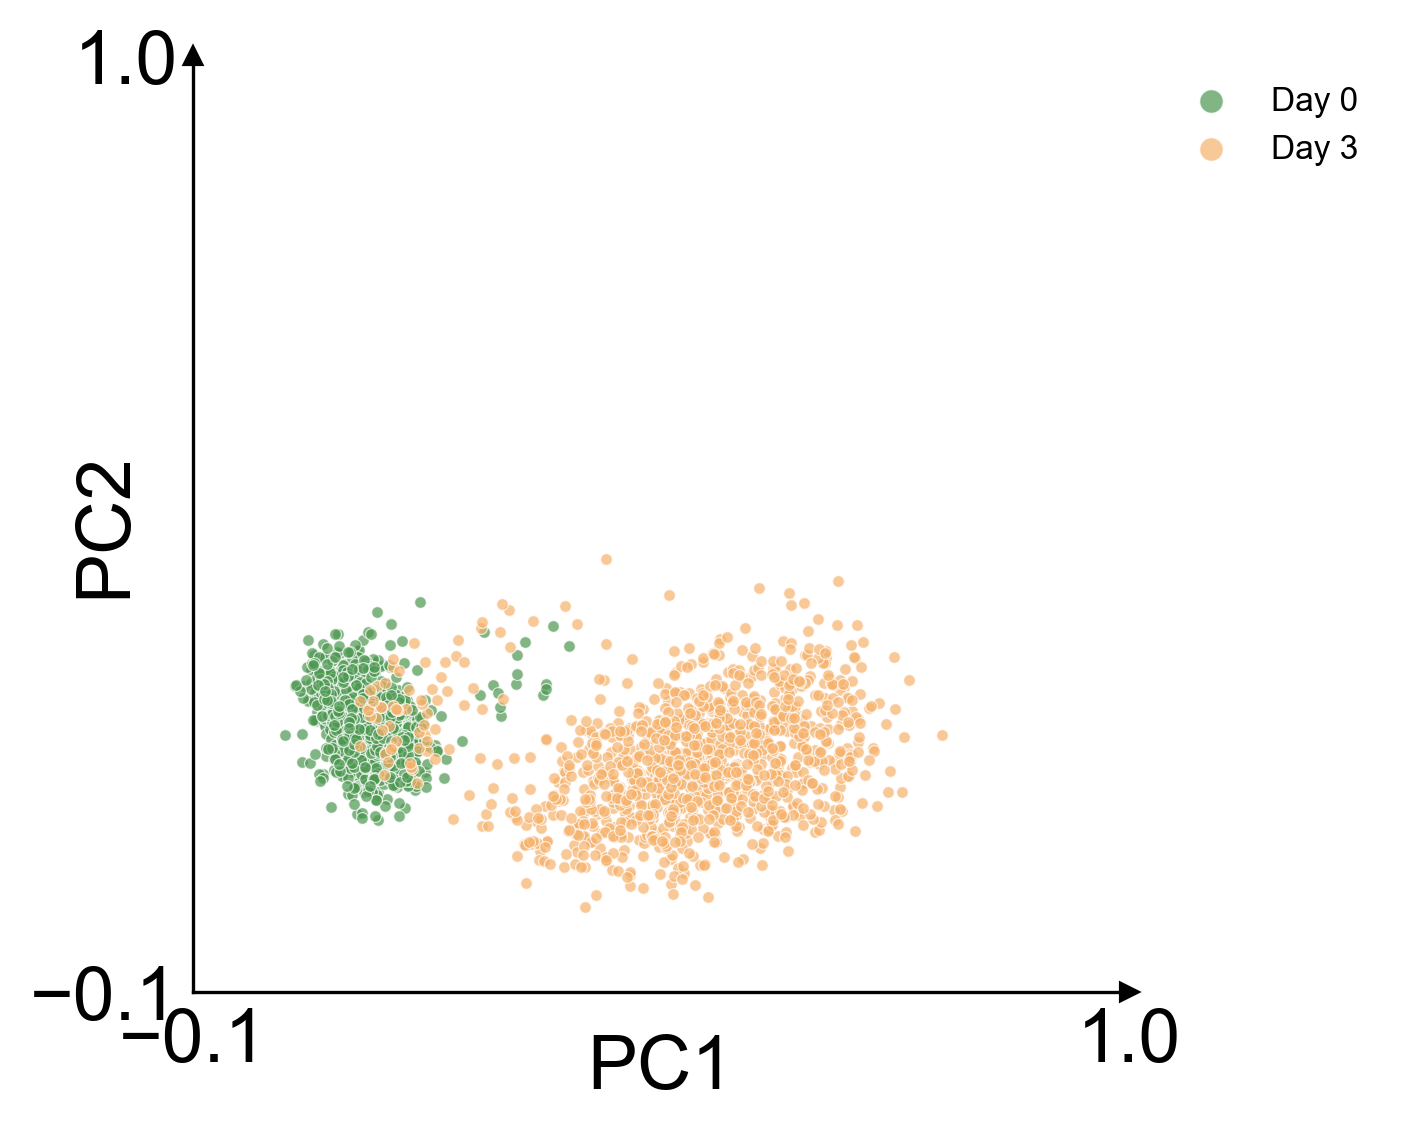

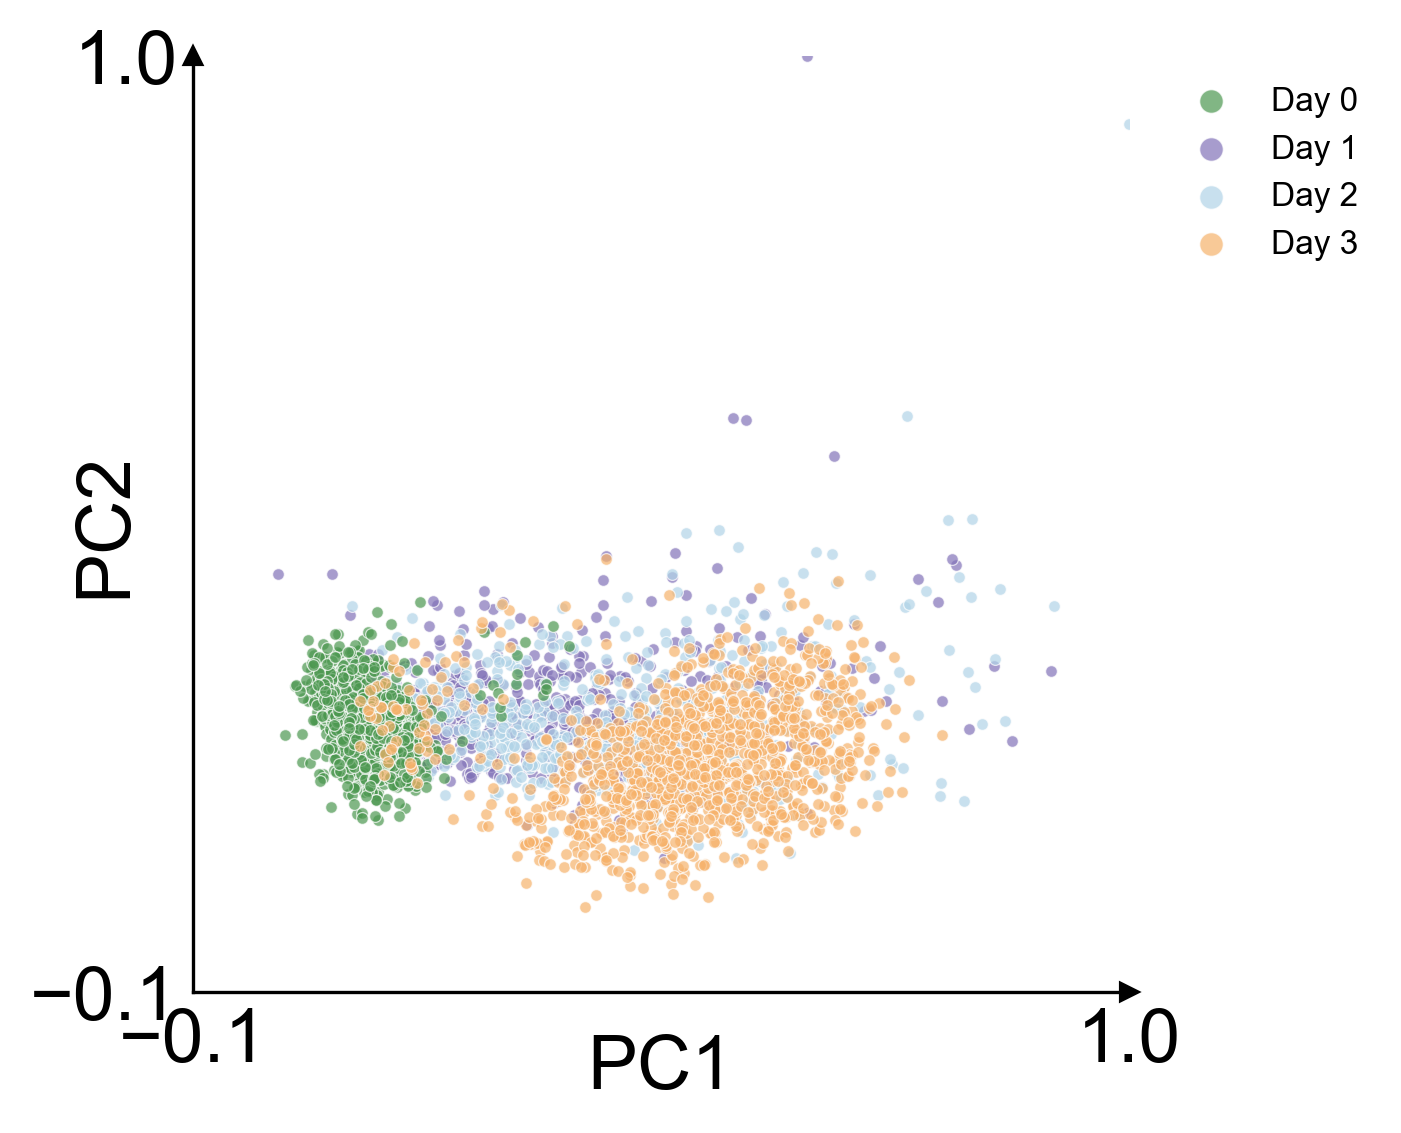

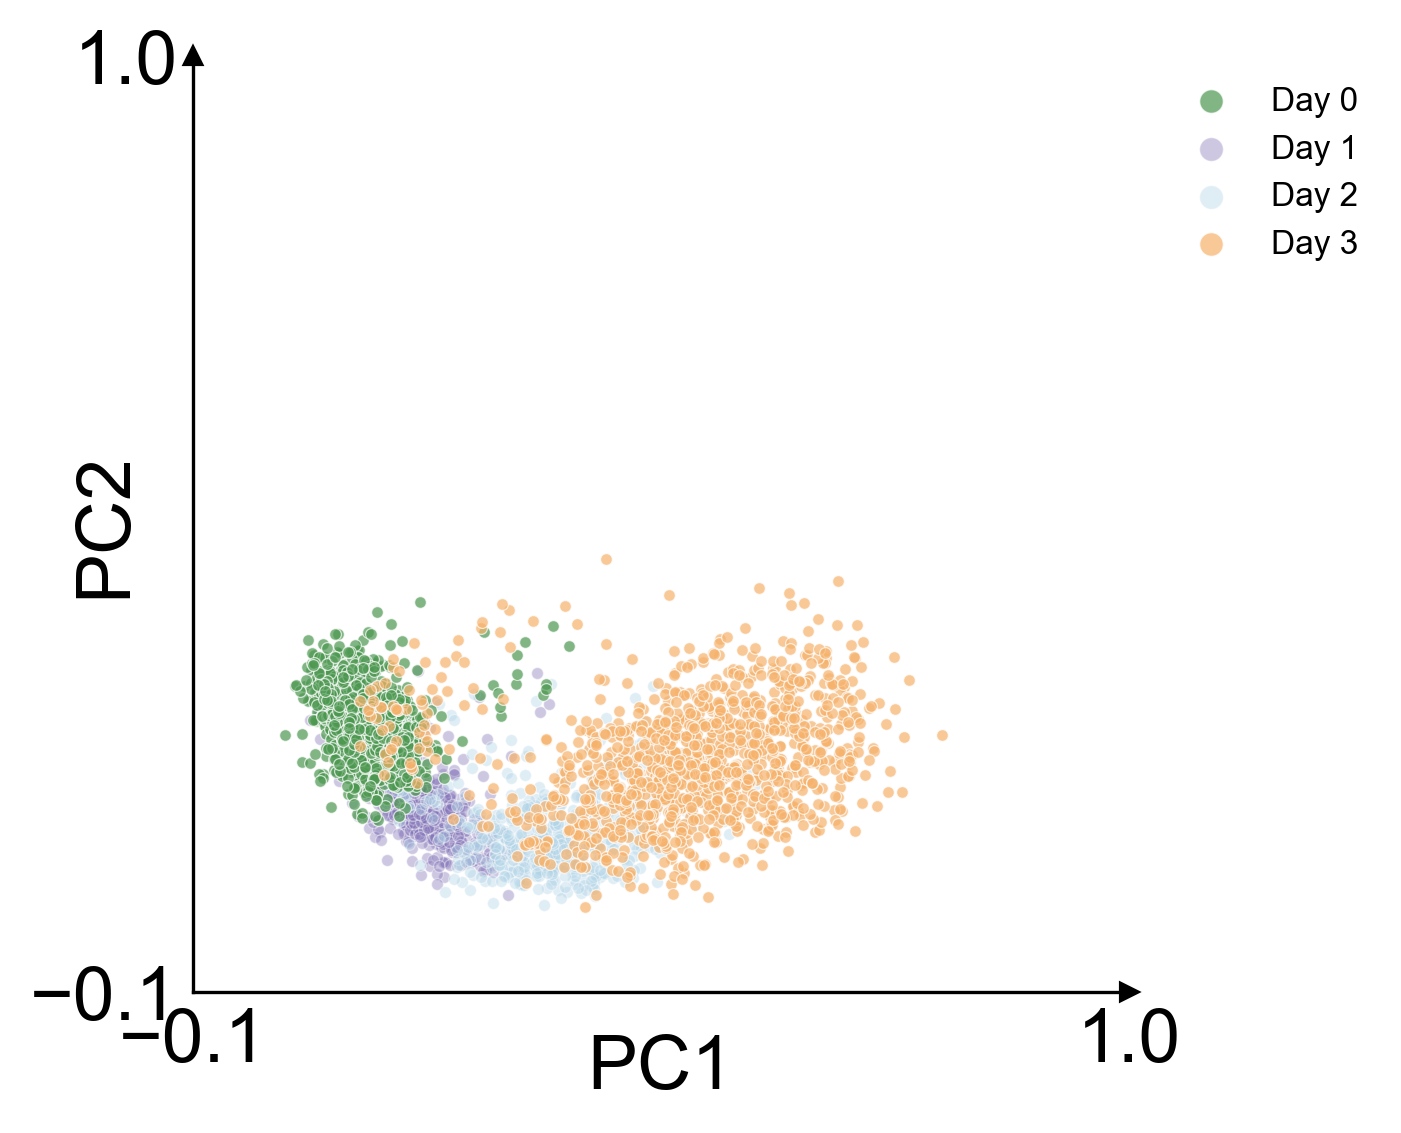

In [1]:
# %load_ext autoreload
# %autoreload 2
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.parent.parent.parent.parent.parent
sys.path.insert(0, str(PROJECT_ROOT))
print(PROJECT_ROOT)

from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson
import scanpy as sc
import os
import anndata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import rc_context
import anndata
import seaborn as sns
import torch
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
import scipy.sparse as sp
print("CUDA Available: ", torch.cuda.is_available())
print("Number of GPUs: ", torch.cuda.device_count())
import numpy as np
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import ndtest
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import DistanceMetric

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from matplotlib import font_manager
font_manager.fontManager.addfont("../../../../arial.ttf")
plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 18,
    "pdf.fonttype": 42,       # Embed TrueType fonts in PDF
})

import anndata as ad
def get_pca_2d(x1, x2, x3, num):
    # Keep day labels before extracting expression matrices.
    datasets = [x1, x2, x3]
    days = [pd.to_numeric(obj.obs["day_types"]).to_numpy()
            for obj in datasets]

    # Align genes by name before computing a shared PCA.
    if not all(obj.var_names.is_unique for obj in datasets):
        raise ValueError("Gene names must be unique in each dataset.")
    genes = x1.var_names[x1.var_names.isin(x2.var_names)
                         & x1.var_names.isin(x3.var_names)]
    if len(genes) < 2:
        raise ValueError("At least two shared genes are required.")

    matrices = []
    for obj in datasets:
        matrix = obj[:, genes].X
        matrices.append(matrix.toarray() if sp.issparse(matrix)
                        else np.asarray(matrix))
    print("Cells in x1, x2, x3:", *(len(matrix) for matrix in matrices))

    # Fit once on all three datasets, as in your original code.
    X_all = np.vstack(matrices)
    coordinates = PCA(n_components=2).fit_transform(X_all)
    coordinates = MinMaxScaler().fit_transform(coordinates)
    split_points = np.cumsum([len(matrix) for matrix in matrices])[:-1]
    points = np.split(coordinates, split_points)

    colors = {0: "#4C9850", 1: "#8273B8",
              2: "#B1D4E7", 3: "#F6B26B"}

    def plot_days(ax, source, selected_days, alpha):
        for day in selected_days:
            mask = days[source] == day
            ax.scatter(
                points[source][mask, 0], points[source][mask, 1],
                s=8, color=colors[day], alpha=alpha,
                edgecolors="white", linewidths=0.3,
                zorder=2 if source == 0 else 1,
                label=f"Day {day}"
            )

    # (output suffix, datasets and days to display)
    panels = [
        ("x1", [(0, [0, 3], 0.7)]),
        ("x1_x2", [(0, [0, 3], 0.7), (1, [1, 2], 0.7)]),
        ("x1_x3_days_1_2", [(0, [0, 3], 0.7), (2, [1, 2], 0.4)]),
    ]

    for suffix, groups in panels:
        fig, ax = plt.subplots(figsize=(5, 5), dpi=300)
        for source, selected_days, alpha in groups:
            plot_days(ax, source, selected_days, alpha)

        ax.set_xlim(-0.1, 1)
        ax.set_ylim(-0.1, 1)
        ax.set_xticks([-0.1, 1])
        ax.set_yticks([-0.1, 1])
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["bottom"].set_visible(True)
        ax.spines["left"].set_visible(True)
        ax.tick_params(axis="both", which="both", length=0)
        ax.plot(1, -0.1, marker=">", color="black", markersize=4,
                transform=ax.get_yaxis_transform(), clip_on=False)
        ax.plot(-0.1, 1, marker="^", color="black", markersize=4,
                transform=ax.get_xaxis_transform(), clip_on=False)
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlabel("PC1", labelpad=-10)
        ax.set_ylabel("PC2", labelpad=-26.5)
        handles, labels = ax.get_legend_handles_labels()
        order = np.argsort(labels)
        ax.legend([handles[i] for i in order], [labels[i] for i in order],
                  loc="upper left", bbox_to_anchor=(1.02, 1),
                  fontsize=8, frameon=False, markerscale=2)
        fig.tight_layout()
        fig.savefig(f"ks_pca_compare_gene_num_{num}_{suffix}.pdf",
                    bbox_inches="tight")
        plt.show()



train_data = sc.read_h5ad("../../input/diff_train.h5ad")
train_data.obs["day_types"] = train_data.obs["Group"]
train_data.obs["class_types"] = "2" 
print(train_data.obs["day_types"].unique())
print(train_data.obs_names)


data_1 = sc.read_h5ad("../experiments/squidiff_exp5_day0_predict_day1.h5ad")
print(data_1)
data_1.obs["day_types"] = 1
print(data_1.obs["day_types"].unique())
data_1.obs_names = [f"{i}-0-day1" for i in range(data_1.n_obs)]
# data_2 = sc.read_h5ad("../experiments/exp5_day0_predict_day2/interception_predict_to_day_2.h5ad")
data_2 = sc.read_h5ad("../experiments/squidiff_exp5_day0_predict_day2.h5ad")
print(data_2)
data_2.obs["day_types"] = 2
print(data_2.obs["day_types"].unique())
data_2.obs_names = [f"{i}-0-day2" for i in range(data_2.n_obs)]
data_squidiff = ad.concat([data_1, data_2], axis=0, join="inner")
print(data_squidiff.shape)
data_squidiff.obs["day_types"] = pd.to_numeric(data_squidiff.obs["day_types"])
data_squidiff.obs["day_types"] = data_squidiff.obs["day_types"].astype("category")
data_squidiff.obs["class_types"] = "1" 
print(data_squidiff.obs["day_types"].unique())
print(data_squidiff)
print(data_squidiff.obs_names)
data_squidiff.var_names = train_data.var_names
print(data_squidiff.var_names)
print(data_squidiff.var_names)

# ground truth day0,day1,day2,day3
test_data_temp = sc.read_h5ad("../../input/diff_test.h5ad")
print("test original data:", test_data_temp)
test_data_temp.obs["day_types"] = test_data_temp.obs["Group"]
# print(train_data.obs)
test_data = test_data_temp[
    test_data_temp.obs["day_types"].isin([1, 2])
].copy()
test_data.obs["class_types"] = "3"

# print(train_data.obs["weight_types"].unique())
print(test_data.obs["day_types"].unique())
print(test_data.obs_names)
# print(train_data.obs["cluster_types"].unique())
#     predict_data = sc.read_h5ad(f"../experiments/exp5_day0_predict_day3_gene_num_{i}/interception_predict_to_day_3.h5ad")
#     print("predict_data:",predict_data)
#     squidiff_data = sc.read_h5ad(f"../../squidiff/experiments/squidiff_exp5_extend_day0_predict_day3_gene_num_{i}.h5ad")
#     print("squidiff_data:",squidiff_data)
#     # get_pairwase_2d(squidiff_data,predict_data, real_adata,i)
get_pca_2d(train_data, data_squidiff, test_data,0)